# Assignment 1 — Image Processing Fundamentals

## Setup

In [54]:
%pip install imagecodecs

   ---------------------------------------- 0.0/19.1 MB ? eta -:--:--
   ---------------------------------------  18.9/19.1 MB 101.1 MB/s eta 0:00:01
   ---------------------------------------- 19.1/19.1 MB 78.1 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [10]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, color, util
from PIL import Image


| Import | Purpose |
|---|---|
| `Path` | Constructs paths to your files |
| `np` | Works with the numerical arrays representing images |
| `plt` | Displays images and plots |
| `io` | Reads and writes image data |
| `color` | Converts between colour representations |
| `util` | Converts image data types and intensity scales |

## A. Image types and file formats

<Peppers> | Shape (384, 512, 3)  | Type  uint8  | Minimum Value Present  0  | Maximum Value Present  255
<Cameraman> | Shape (256, 256)  | Type  uint8  | Minimum Value Present  7  | Maximum Value Present  253


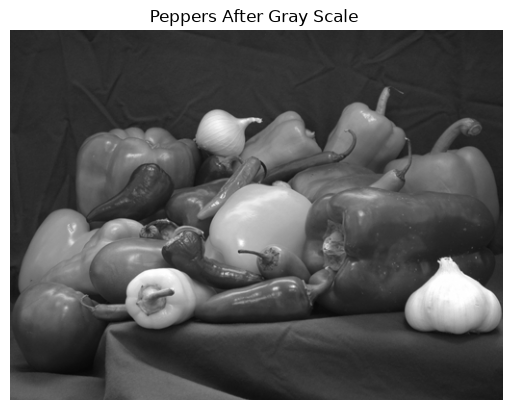

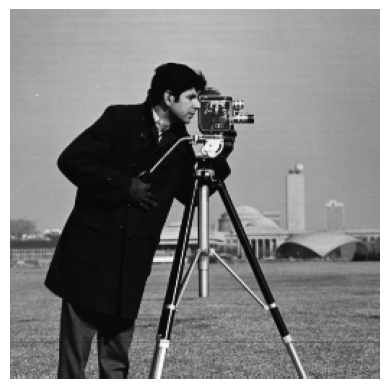

In [11]:
##################
##      A1      ##
##################

#loads images into a numpy array (via io.imread)
original_peppers = io.imread(Path("data") / "peppers.png")
original_cameraman = io.imread(Path("data") / "cameraman.tif")

#display image details
print("<Peppers> | Shape", original_peppers.shape, " | Type ", original_peppers.dtype, " | Minimum Value Present ", original_peppers.min()," | Maximum Value Present ", original_peppers.max())
print("<Cameraman> | Shape", original_cameraman.shape, " | Type ", original_cameraman.dtype, " | Minimum Value Present ", original_cameraman.min()," | Maximum Value Present ", original_cameraman.max())

#convert peppers rgb to gray at a normalized 0 - 1 scale
original_pepper_gray = color.rgb2gray(original_peppers)

#display peppers after gray transformation
plt.figure()
#ensure "imshow" doesn't apply a default color map, vmin and vmax sets display range
plt.imshow(original_pepper_gray, cmap ="gray", vmin = 0, vmax =1)
plt.title("Peppers After Gray Scale ")
plt.axis("off")
plt.show()

#display Cameraman 
plt.figure()
#ensure "imshow" doesn't apply a default color map, vmin and vmax sets display range (uint8 is 0-255)
plt.imshow(original_cameraman, cmap ="gray", vmin = 0, vmax = 255)
plt.axis("off")
plt.show()


In [3]:
##################
##      A2      ##
##################

#convert from 0-1 (floating point values, end up mixing rounding error from conversion and error from compression) to 8-bit (0-255) scale
original_pepper_gray = util.img_as_ubyte(original_pepper_gray)

#create output path if necessary via mkdir
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)
#creates Pillow image from Numpy array
image_to_save = Image.fromarray(original_pepper_gray)

#lossless, tif and png, note lzw compression is lossless
image_to_save.save(output_dir / "original_pepper_gray.png")
image_to_save.save(output_dir / "original_pepper_gray.tif",compression="tiff_lzw")
#95, 75, and 50 qualities
image_to_save.save(output_dir / "original_pepper_gray_90.jpg", quality=90)
image_to_save.save(output_dir / "original_pepper_gray_75.jpg", quality=75)
image_to_save.save(output_dir / "original_pepper_gray_50.jpg", quality=50)

filenames = [
    "original_pepper_gray.png",
    "original_pepper_gray.tif",
    "original_pepper_gray_90.jpg",
    "original_pepper_gray_75.jpg",
    "original_pepper_gray_50.jpg"
]
for filename in filenames:
    saved_path = output_dir / filename
    file_size_bytes = saved_path.stat().st_size
    print(f"{filename}: {file_size_bytes} bytes")

original_pepper_gray.png: 96970 bytes
original_pepper_gray.tif: 146908 bytes
original_pepper_gray_90.jpg: 33173 bytes
original_pepper_gray_75.jpg: 18818 bytes
original_pepper_gray_50.jpg: 12422 bytes


MSE: 0.00000000
PSNR: inf dB
MSE: 0.00000000
PSNR: inf dB
MSE: 0.00003490
PSNR: 44.57 dB
MSE: 0.00007937
PSNR: 41.00 dB
MSE: 0.00013796
PSNR: 38.60 dB


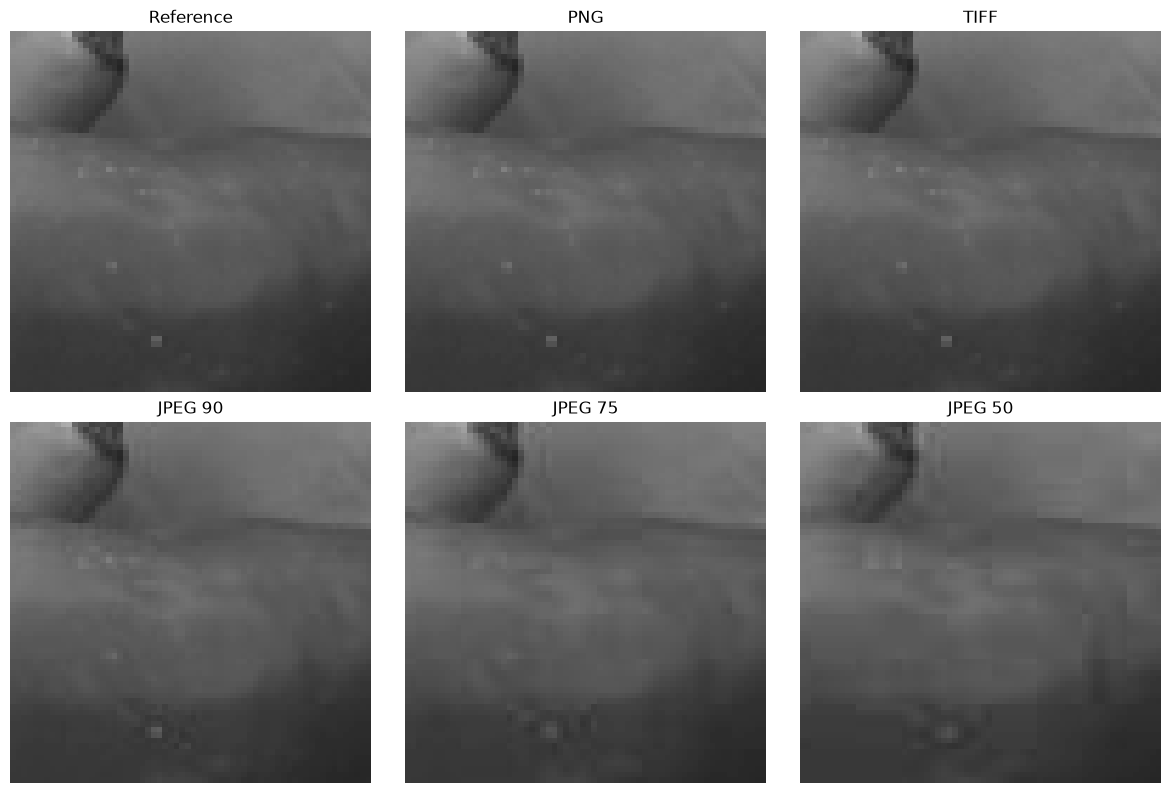

In [ ]:
##################
##      A3     ##
##################
outputs_path = "outputs"
gray_peppers_png = io.imread(Path(outputs_path) / "original_pepper_gray.png")
gray_peppers_tif = io.imread(Path(outputs_path) / "original_pepper_gray.tif")
gray_peppers_jpg_90 = io.imread(Path(outputs_path) / "original_pepper_gray_90.jpg")
gray_peppers_jpg_75 = io.imread(Path(outputs_path) / "original_pepper_gray_75.jpg")
gray_peppers_jpg_50 = io.imread(Path(outputs_path) / "original_pepper_gray_50.jpg")

peppers_file_types = [
    gray_peppers_png,
    gray_peppers_tif,
    gray_peppers_jpg_90,
    gray_peppers_jpg_75,
    gray_peppers_jpg_50
]

### MSE & PSNR between original_pepper_gray and [array]
for filetype in peppers_file_types:
    #convert to float on 0-1 scale for all images
    reference = util.img_as_float(original_pepper_gray)
    reloaded = util.img_as_float(filetype)

    #MSE calculation
    mse = np.mean((reference - reloaded)**2)
    print(f"MSE: {mse:.8f}")

    # Peak signal-to-noise ratio; maximum intensity is 1 on this scale
    if mse == 0:
        psnr = np.inf
    else:
        psnr = 10 * np.log10(1.0 ** 2 / mse)
    print(f"PSNR: {psnr:.2f} dB")

### Cropping (Selecting a smaller rectangle from an array)

#USED TO FIND A SUITABLE LOCATION OF COMPRESSION ARTIFACTS
#plt.figure(figsize=(10, 8))
#plt.imshow(gray_peppers_png, cmap="gray", vmin=0, vmax=255)
#plt.title("Choose a crop: x = column, y = row")
#plt.show()

#plt.figure(figsize=(10, 8))
#plt.imshow(gray_peppers_jpg_50, cmap="gray", vmin=0, vmax=255)
#plt.title("Choose a crop: x = column, y = row")
#plt.show()

r0 = 150   # Starting row: y coordinate
c0 = 390   # Starting column: x coordinate
crop_size = 64

images = [
    ("Reference", original_pepper_gray),
    ("PNG", gray_peppers_png),
    ("TIFF", gray_peppers_tif),
    ("JPEG 90", gray_peppers_jpg_90),
    ("JPEG 75", gray_peppers_jpg_75),
    ("JPEG 50", gray_peppers_jpg_50),
]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, (label, image) in zip(axes.flat, images):
    image_float = util.img_as_float(image)

    crop = image_float[r0:r0 + crop_size, c0:c0 + crop_size]

    ax.imshow( crop, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(label)
    ax.axis("off")

plt.tight_layout()
plt.show()


* **MSE:** Compares the error/difference between the pixels at the same location. LOW = less difference, HIGH(like 1) = more difference
* **PSNR:** Gives the noise gained through the saving and reconstructing of the image. LOW = more reconstruction error, HIGH(inf) = less reconstruction error

Global threshold: 0.49356617647058826
Global: foreground = 22344, background = 51456, total = 73800
Global inverted: foreground = 51456, background = 22344, total = 73800
Adaptive: foreground = 27897, background = 45903, total = 73800
Adaptive inverted: foreground = 45903, background = 27897, total = 73800


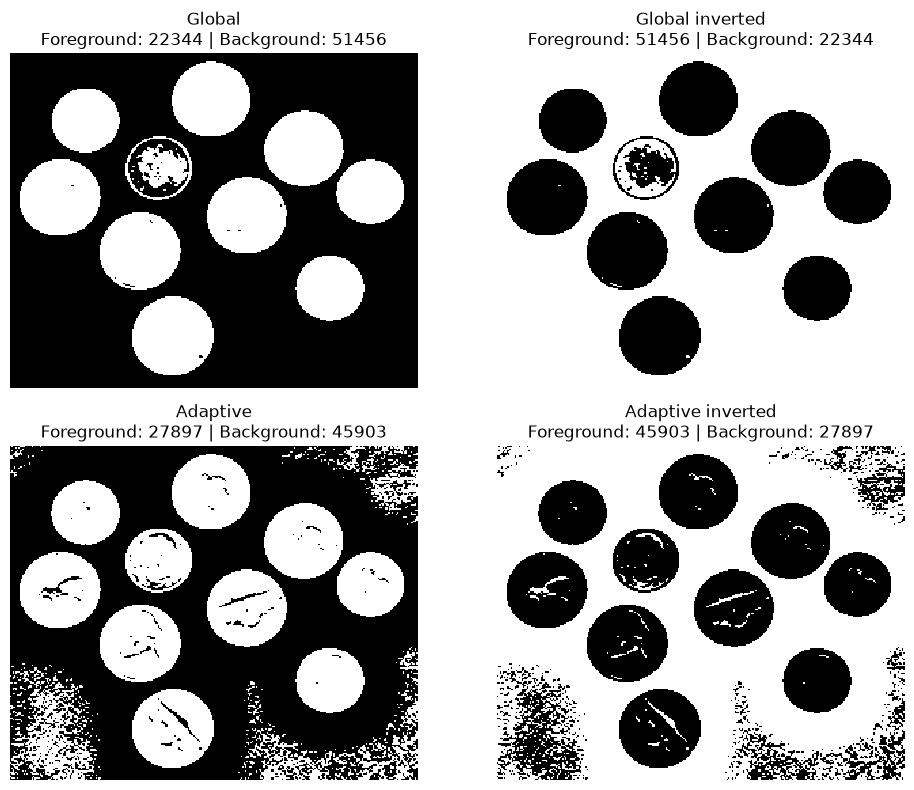

In [ ]:
##################
##      A4      ##
##################
from skimage import filters

coins = io.imread(Path("data") / "coins.png")
coins_float = util.img_as_float(coins)

# Global
global_threshold = filters.threshold_otsu(coins_float)
print("Global threshold:", global_threshold)
global_mask = coins_float > global_threshold
#   Inversion
global_inverted = ~global_mask

# Adaptive
#the higher the block size the more it is averaging over, it becomes easier to see the individual coins but the faces become obscurred
local_thresholds = filters.threshold_local(coins_float, block_size=83)
adaptive_mask = coins_float > local_thresholds
#   Inversion
adaptive_inverted = ~adaptive_mask

# Pair each display label with its Boolean mask
results = [
    ("Global", global_mask),
    ("Global inverted", global_inverted),
    ("Adaptive", adaptive_mask),
    ("Adaptive inverted", adaptive_inverted)
]

# Create four plotting panels
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

# Visit each panel and its corresponding mask
for ax, (label, mask) in zip(axes.flat, results):

    # True pixels are foreground; False pixels are background
    foreground = np.count_nonzero(mask)
    background = mask.size - foreground

    print(
        f"{label}: foreground = {foreground}, "
        f"background = {background}, total = {mask.size}"
    )

    # Display False as black and True as white
    ax.imshow(
        mask,
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )

    ax.set_title(
        f"{label}\n"
        f"Foreground: {foreground} | Background: {background}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

## B. Intensity transforms and geometry

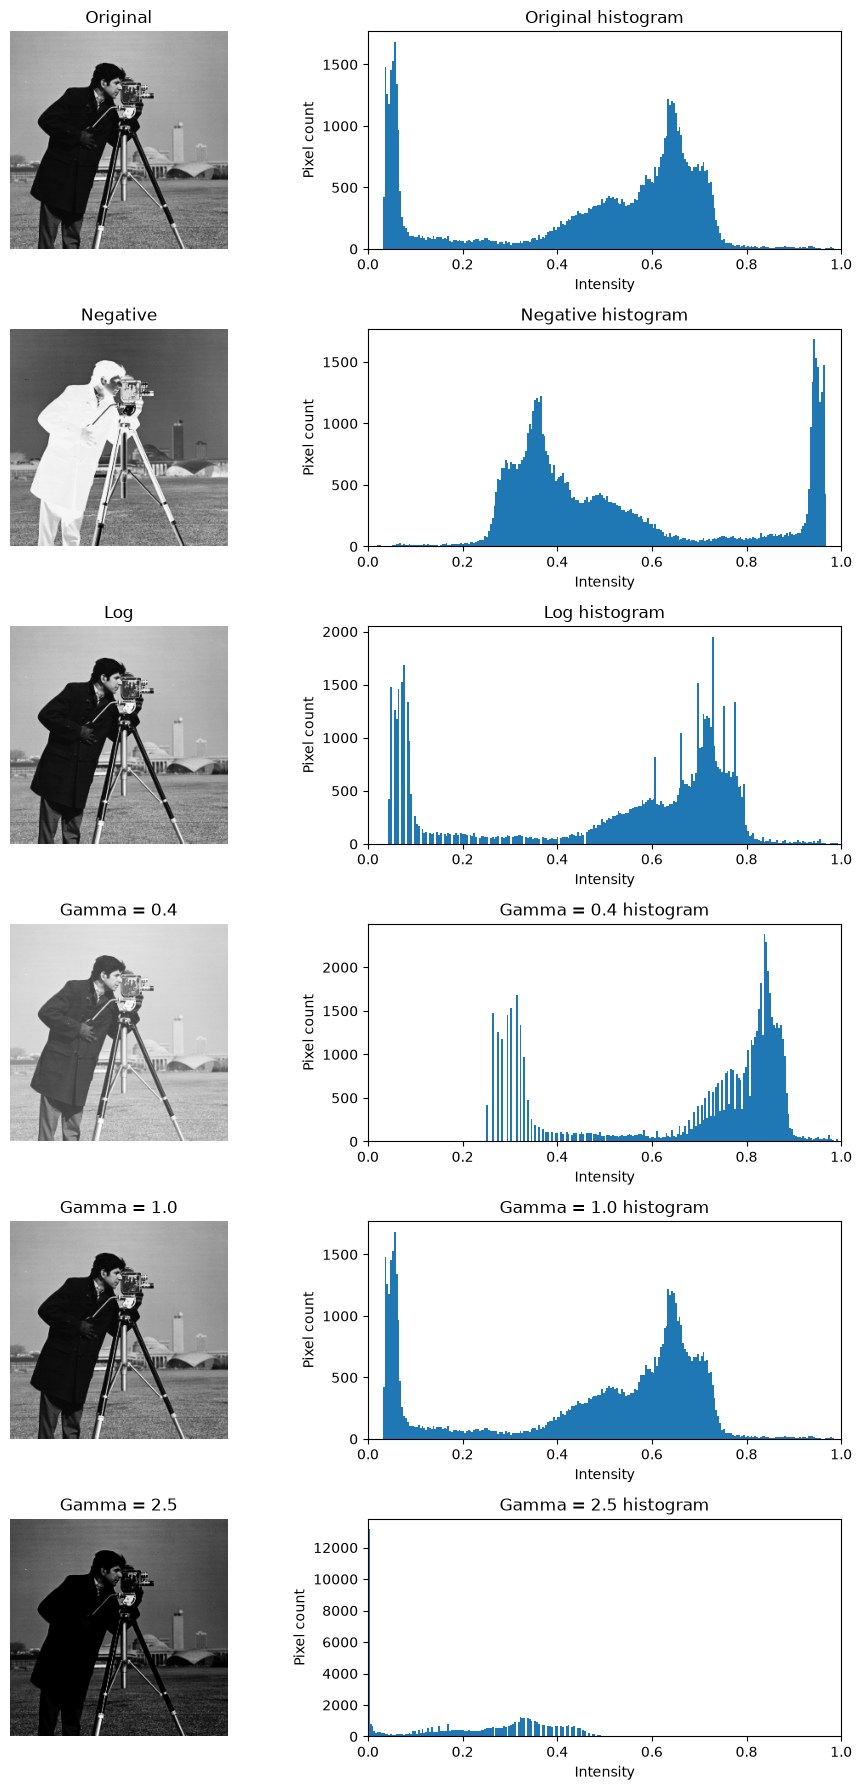

In [35]:
##################
##      B1      ##
##################

I = util.img_as_float(original_cameraman)

I_negative = 1 - I
I_log = (np.log1p (I) /  np.log(2))

# Store each label together with its image
results = [
    ("Original", I),
    ("Negative", I_negative),
    ("Log", I_log)
]

for gamma in [0.4, 1.0, 2.5]:
    I_gamma = I ** gamma
    results.append((f"Gamma = {gamma}", I_gamma))

# One row per result: image on the left, histogram on the right
fig, axes = plt.subplots(
    len(results), 2,
    figsize=(10, 3 * len(results))
)

for row, (label, image) in enumerate(results):
    axes[row, 0].imshow(image, cmap="gray", vmin=0, vmax=1)
    axes[row, 0].set_title(label)
    axes[row, 0].axis("off")

    axes[row, 1].hist(image.ravel(), bins=256, range=(0, 1))
    axes[row, 1].set_title(f"{label} histogram")
    axes[row, 1].set_xlabel("Intensity")
    axes[row, 1].set_ylabel("Pixel count")
    axes[row, 1].set_xlim(0, 1)

plt.tight_layout()
plt.show()



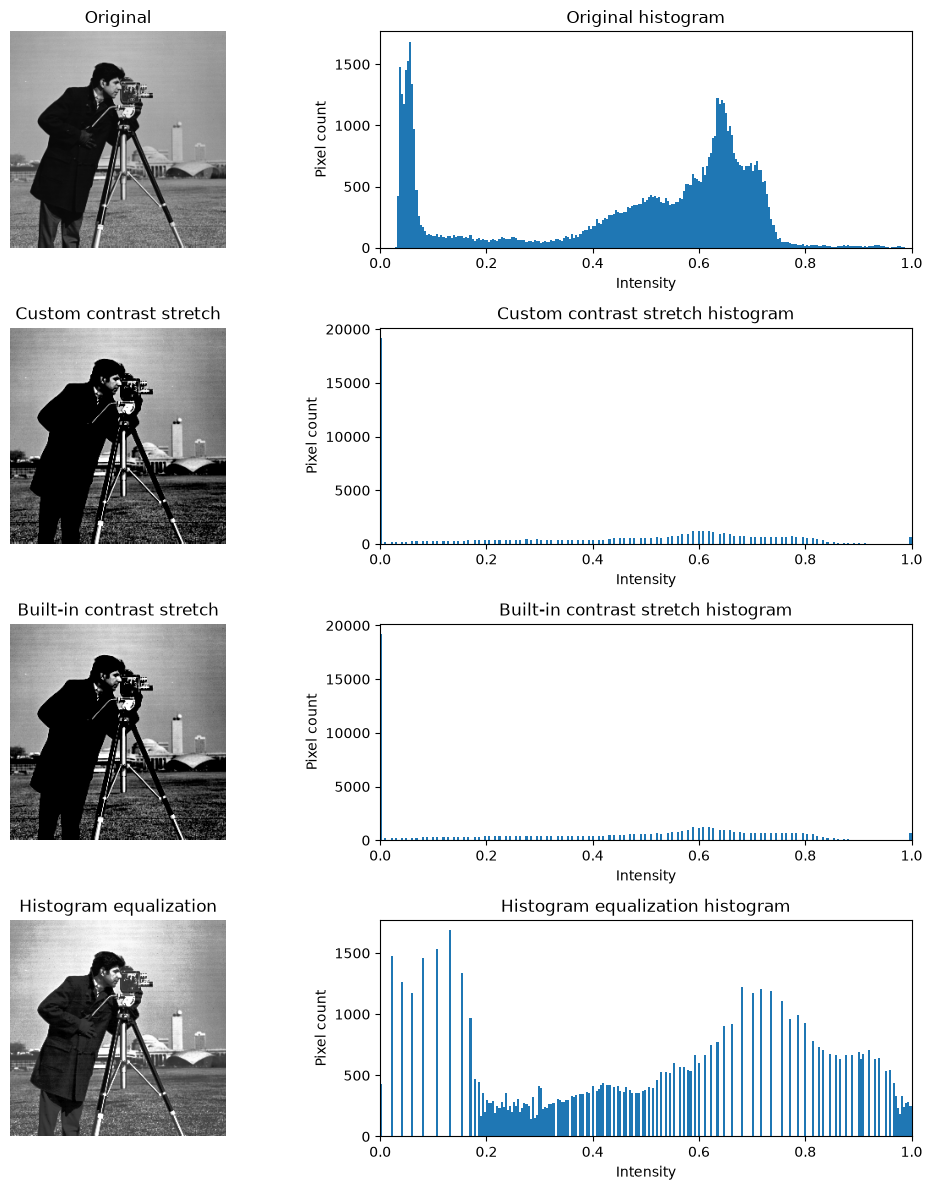

In [46]:
##################
##      B2      ##
##################

def contrastStretch(I, input_range, output_range):
    r1, r2 = input_range #for example: 0.2 - 0.8
    s1, s2 = output_range #for example: 0.0 - 1.0

    # Implement your mapping here
    fraction = (I-r1)/(r2  - r1)
    stretched = s1 + fraction * (s2 - s1)
    return np.clip(stretched, s1, s2)
    

from skimage import exposure

I = util.img_as_float(original_cameraman)

# Example settings—use the same endpoints for both stretches
input_range = (0.4, 0.8)
output_range = (0.0, 1.0)

custom_stretch = contrastStretch(I, input_range, output_range)

builtin_stretch = exposure.rescale_intensity(
    I,
    in_range=input_range,
    out_range=output_range
)

equalized = exposure.equalize_hist(I)

results = [
    ("Original", I),
    ("Custom contrast stretch", custom_stretch),
    ("Built-in contrast stretch", builtin_stretch),
    ("Histogram equalization", equalized)
]

# Each row contains an image and its histogram
fig, axes = plt.subplots(4, 2, figsize=(11, 12))

for row, (label, image) in enumerate(results):
    axes[row, 0].imshow(image, cmap="gray", vmin=0, vmax=1)
    axes[row, 0].set_title(label)
    axes[row, 0].axis("off")

    axes[row, 1].hist(image.ravel(), bins=256, range=(0, 1))
    axes[row, 1].set_title(f"{label} histogram")
    axes[row, 1].set_xlabel("Intensity")
    axes[row, 1].set_ylabel("Pixel count")
    axes[row, 1].set_xlim(0, 1)

plt.tight_layout()
plt.show()

* **Original Vs Custom Stretched:** Mapping intensity values from 0.4-0.8 proves to bring lighter parts of the picture forward, and make darker parts dark (I assume through clipping)
* **Custom Vs Built-In Stretched:** For some reason mapping 0.4-0.8 looks almost identical to built-in (both in picture and in histogram), I believe this is because built-in also does linear stretching, so giving it the same ranges yeilds the same results
* **Stretching Vs Equalization:** Eq. easily comes out on top, I think this is because it nonlinearly is able to stretch intensities, coming in handy with the dark similar intensity features found on the jacket for example, it is the clearest picture of them all in that regard

Crop shape: (256, 256, 3)


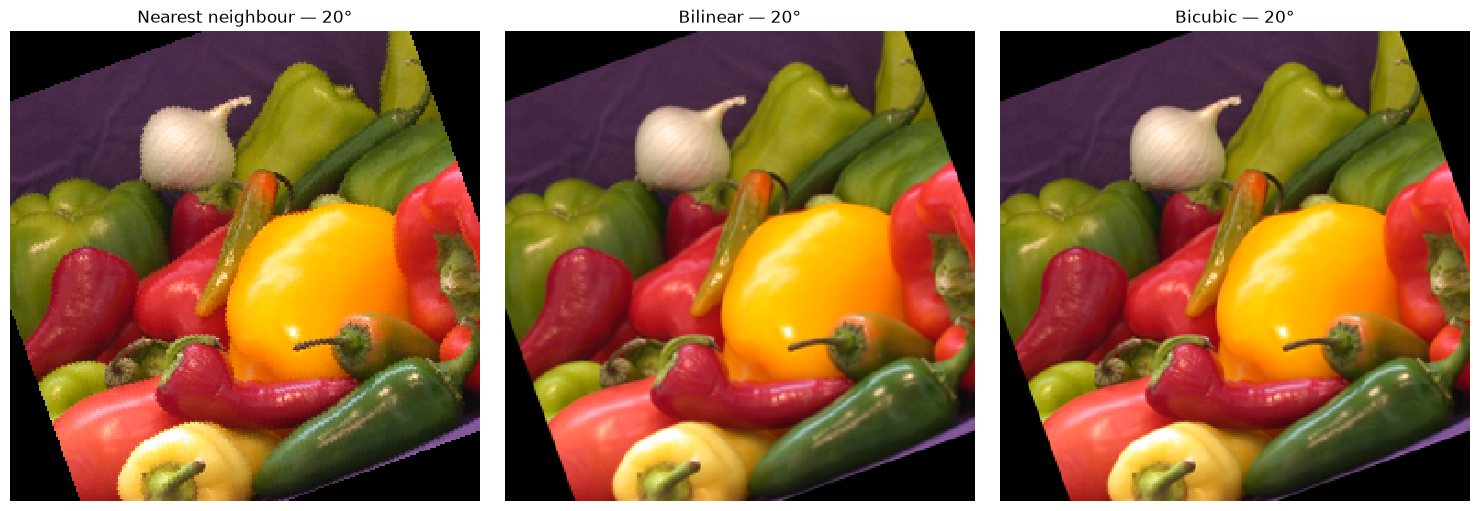

Nearest neighbour: 300% view


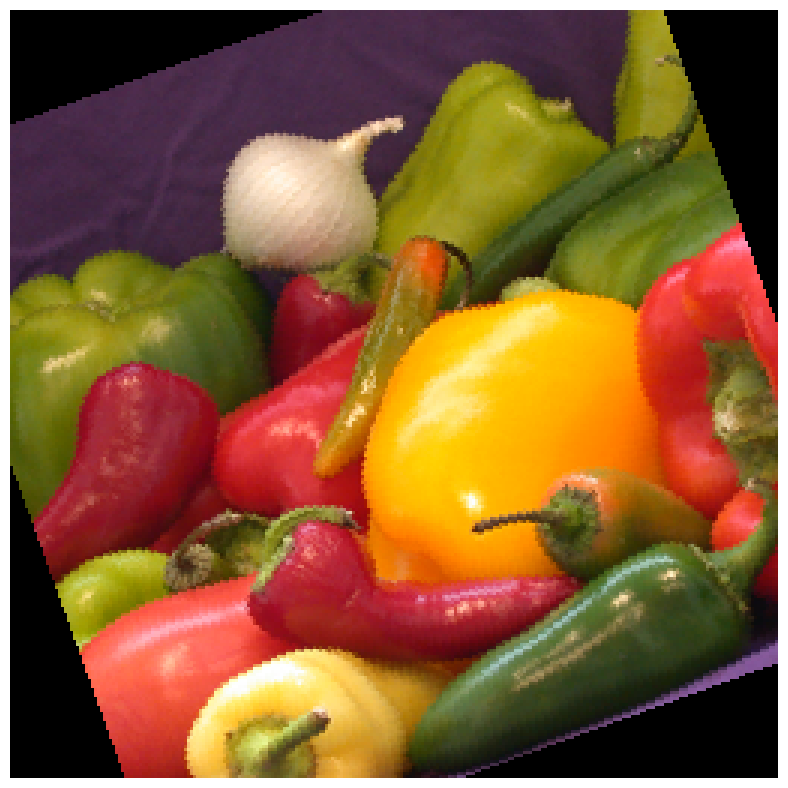

Bilinear: 300% view


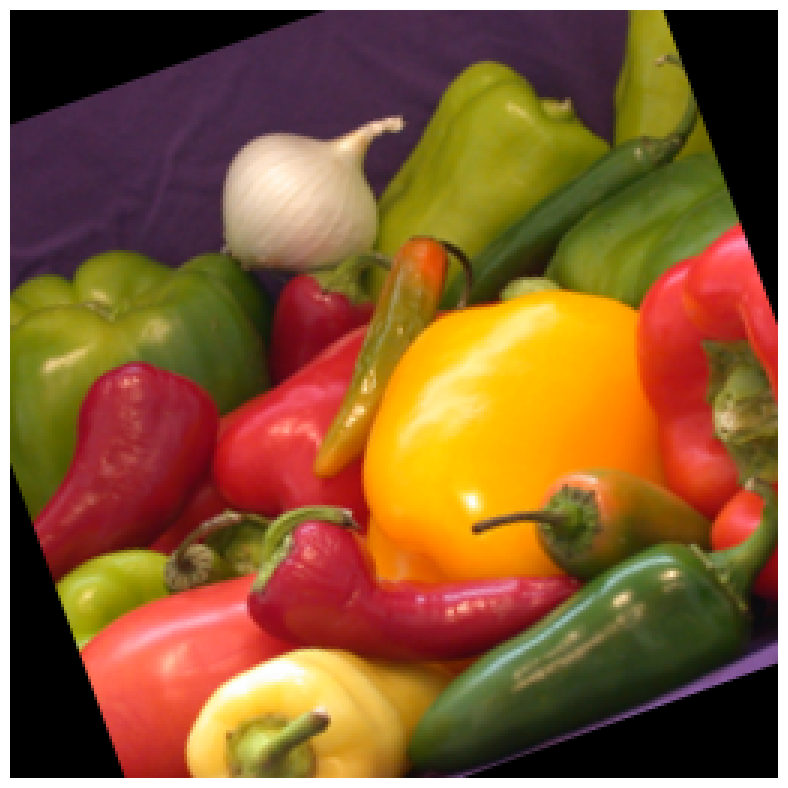

Bicubic: 300% view


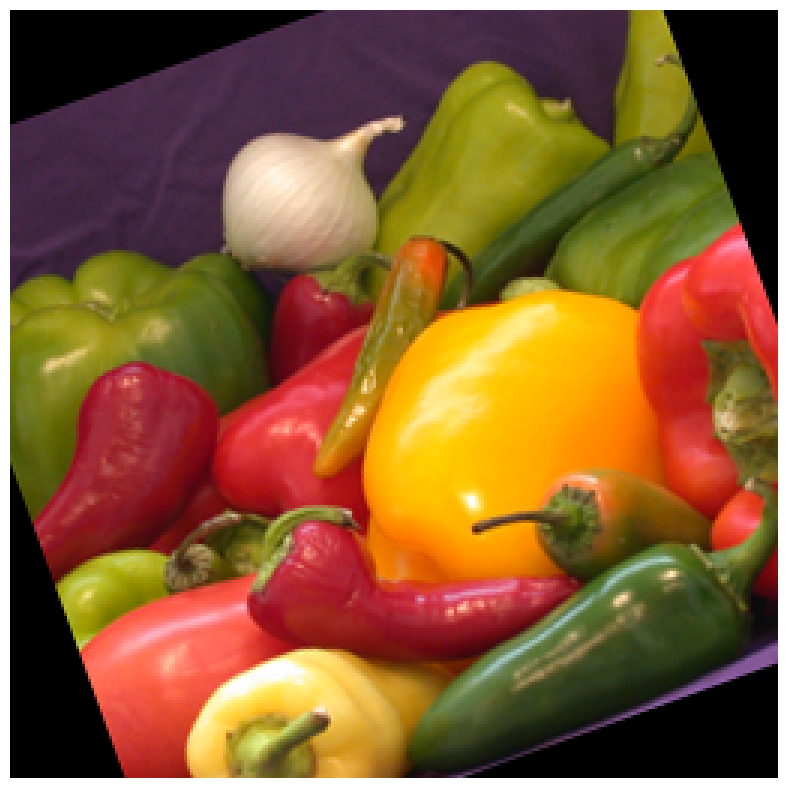

In [49]:
##################
##      B3      ##
##################
from skimage import transform

# Choose a starting point that leaves room for the full crop
r0, c0 = 50, 100

crop = original_peppers[r0:r0 + 256, c0:c0 + 256]
print("Crop shape:", crop.shape)  # Should be (256, 256, 3)

crop_float = util.img_as_float(crop)

methods = [
    ("Nearest neighbour", 0),
    ("Bilinear", 1),
    ("Bicubic", 3)
]

rotated_images = []

for label, order in methods:
    rotated = transform.rotate(
        crop_float,
        angle=20,
        order=order,
        resize=False,
        mode="constant",
        cval=0
    )
    rotated_images.append((label, rotated))

#Display Results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (label, image) in zip(axes, rotated_images):
    ax.imshow(image, interpolation="nearest")
    ax.set_title(f"{label} — 20°")
    ax.axis("off")

plt.tight_layout()
plt.show()

#300% view
for label, image in rotated_images:
    zoomed = np.repeat(np.repeat(image, 3, axis=0), 3, axis=1)

    # 768 × 768 display pixels: three times the 256 × 256 image
    fig = plt.figure(figsize=(7.68, 7.68), dpi=100)
    ax = fig.add_axes([0, 0, 1, 1])
    ax.imshow(zoomed, interpolation="nearest")
    ax.axis("off")

    print(f"{label}: 300% view")
    plt.show()

* **Nearest Neighbour -** By far the worst aliasing, there is significant artifacting along any visible edge. I believe this is because it does not do any blending 
* **Bicubic & Bilinear** - To the naked eye it does not seem like they have any significant difference between the two, but against NN it is significantly better. I beleive this is due to the fact that they both blend surrounding pixels for smoother transitions

## C. Spatial filtering

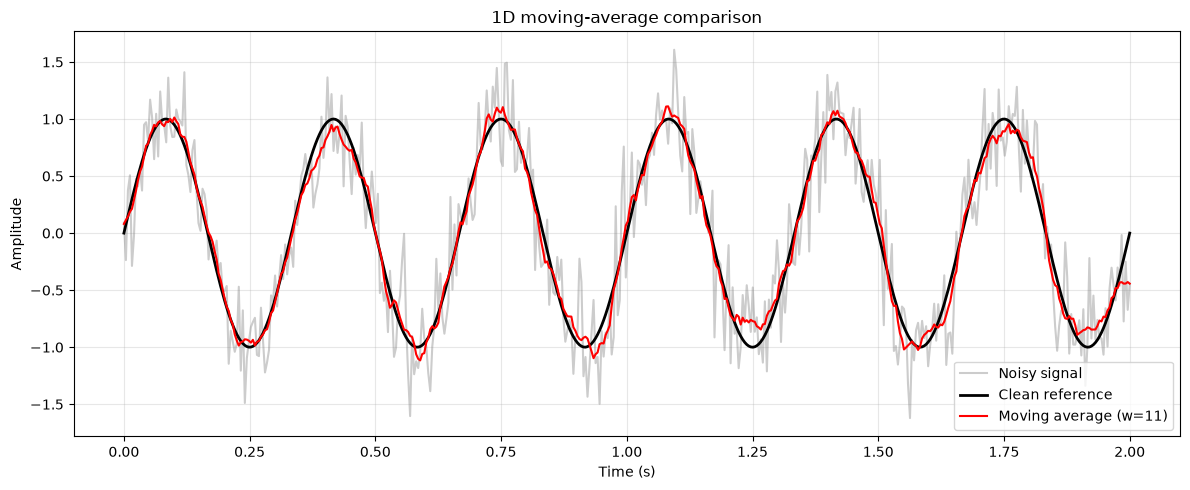

Maximum difference: 3.3306690738754696e-16


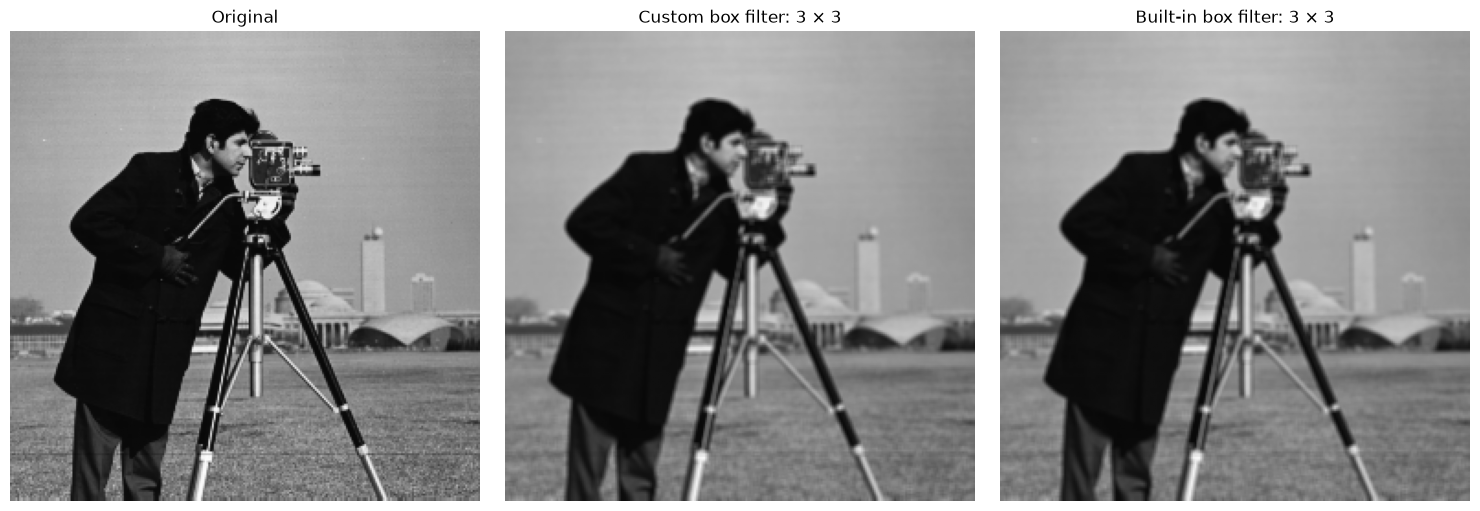

In [ ]:
##################
##      C1      ##
##################

import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
from skimage import util

I = util.img_as_float(original_cameraman)

def movingAverage1D(x, w):
    x = np.asarray(x, dtype=float)

    #padding allows for the averages to be calculated at the edges, where to the left
        #/right there exist no values ( 1 12345 5)
    padding = w // 2
    padded = np.pad(x, padding, mode="edge")
    output = np.empty_like(x)

    for i in range(len(x)):
        window = padded[i:i + w]
        output[i] = np.sum(window) / w

    return output

## Testing moving average on a 1D signal ###############

#generating a noist signal & filtering it
rng = np.random.default_rng(42)
t = np.linspace(0, 2, 500)
clean = np.sin(2 * np.pi * 3 * t)
noisy = clean + rng.normal(0, 0.3, size=t.shape)
filtered = movingAverage1D(noisy, 11)

##PLOTTING/DISPLAY
plt.figure(figsize=(12, 5))

plt.plot(t, noisy, label="Noisy signal", color="gray", alpha=0.4)
plt.plot(t, clean, label="Clean reference", color="black", linewidth=2)
plt.plot(t, filtered, label="Moving average (w=11)", color="red")

plt.title("1D moving-average comparison")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
## Testing moving average on a 1D signal ###############

## Implementing boxFilter2D ##############
k = 3
def boxFilter2D(I, k):
    padding = k // 2
    padded = np.pad(I, padding, mode="edge")
    output = np.empty_like(I)

    rows, columns = I.shape

    for row in range(rows):
        for column in range(columns):
            window = padded[row:row + k, column:column + k]
            output[row, column] = np.sum(window) / (k * k)
    return output

custom = boxFilter2D(I, k)

kernel = np.ones((k, k), dtype=float) / (k * k)
builtin = ndimage.convolve(I, kernel, mode="nearest")

print("Maximum difference:", np.max(np.abs(custom - builtin)))
## Implementing boxFilter2D on a cameraman##############
k = 3
# My implementation
custom = boxFilter2D(I, k)
# Normalized averaging kernel so that all weights of pixels are equivalent
kernel = np.ones((k, k), dtype=float) / (k * k)
# built in box filter
builtin = ndimage.convolve(I, kernel, mode="nearest")
results = [
    ("Original", I),
    (f"Custom box filter: {k} × {k}", custom),
    (f"Built-in box filter: {k} × {k}", builtin)
]

#plotting
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (label, image) in zip(axes, results):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(label)
    ax.axis("off")
plt.tight_layout()
plt.show()



* The difference between the custom box filter and the built in box filter seems to be negligble, but they are achieving and applying the same principles so I assume this is the expected result.

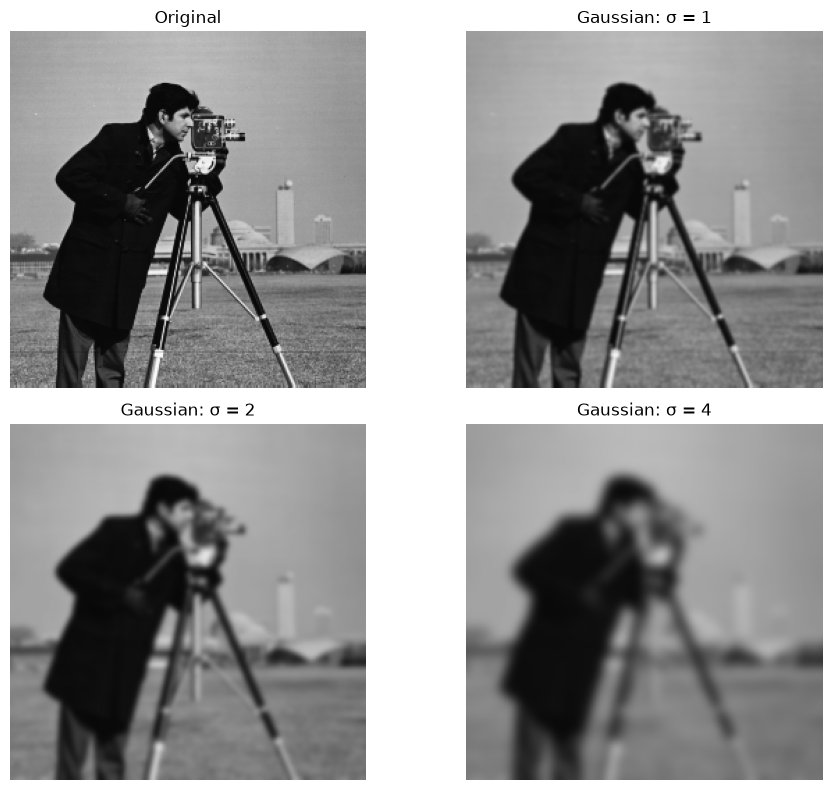

In [ ]:
##################
##      C2      ##
##################

from pathlib import Path
import matplotlib.pyplot as plt
from scipy import ndimage
from skimage import io, util

original_cameraman = io.imread(Path("data") / "cameraman.tif")
I = util.img_as_float(original_cameraman)

results = [("Original", I)]

#Applying the internal gaussian filter and displaying it
for sigma in [1, 2, 4]:
    blurred = ndimage.gaussian_filter(I,sigma=sigma,mode="nearest")
    results.append((f"Gaussian: σ = {sigma}", blurred))
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (label, image) in zip(axes.flat, results):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(label)
    ax.axis("off")
plt.tight_layout()
plt.show()

* Sigma = 1 seems to be the best filtering, the other two loose to many fine details to reasonably discern things from the picture, even though they reduce noise the most. Sigma 1 is objectively the clearest of the three while still incorporating noise reduction.

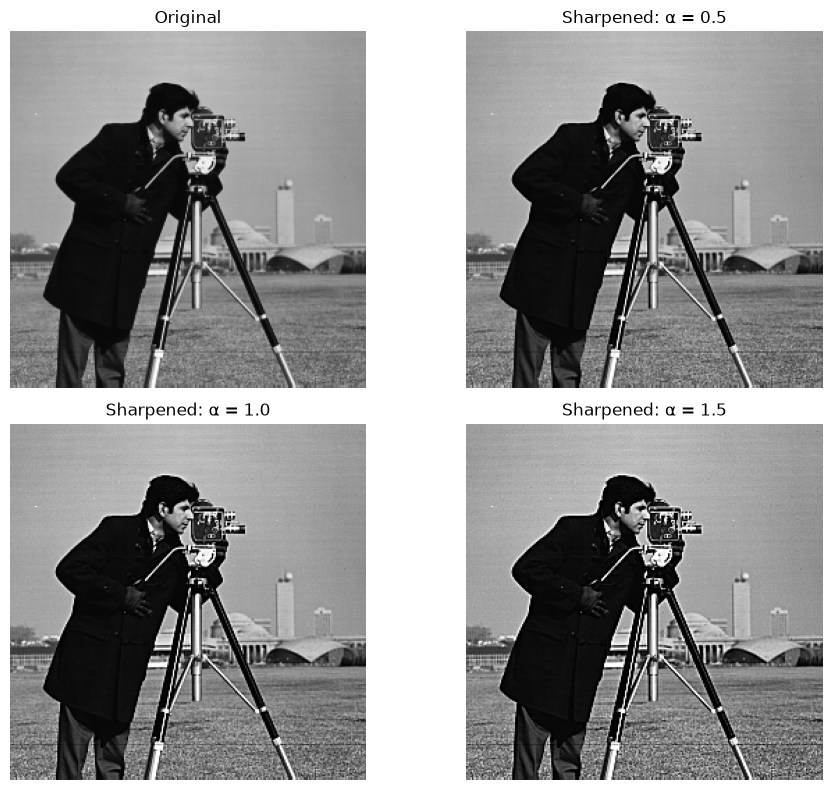

In [35]:
##################
##      C3      ##
##################

import numpy as np
I = util.img_as_float(original_cameraman)
# Fix the blur strength so only alpha changes
I_blur = ndimage.gaussian_filter(I, sigma=1, mode="nearest")

# detail extracts the details removed by blurring
detail = I - I_blur
results = [("Original", I)]
for alpha in [0.5, 1.0, 1.5]:
    #this adds them back at a factor of the alpha, so if one side got lighter and the other
    ###darker during blurring we can use that to scale them again on regular image, ergo sharpening it
    I_sharp = I + alpha * detail
    # Keep I_sharp unchanged; clip a separate version for display
    display_image = np.clip(I_sharp, 0, 1)
    results.append((f"Sharpened: α = {alpha}", display_image))

#Display the results
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (label, image) in zip(axes.flat, results):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(label)
    ax.axis("off")
plt.tight_layout()
plt.show()


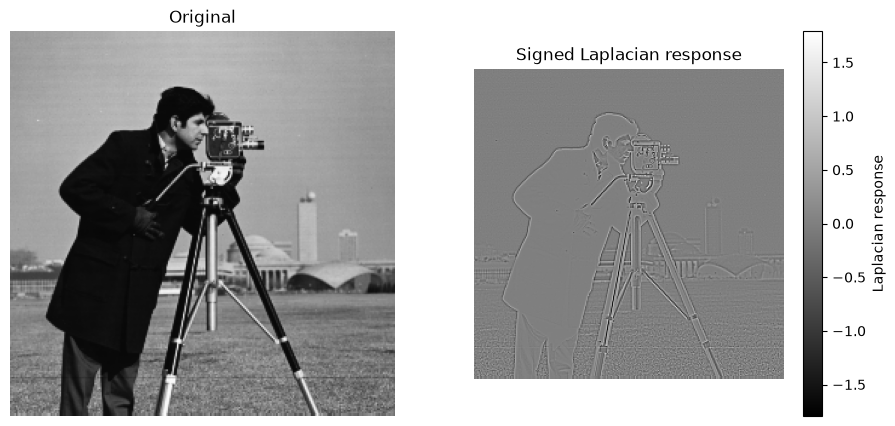

In [37]:
##################
##      C4      ##
##################

I = util.img_as_float(original_cameraman)

# The kernel essentially compares a pixel against its neighbours to see quickl changes in brightness
a = 0.2
kernel = np.array([
    [a,     1 - a,  a],
    [1 - a, -4,     1 - a],
    [a,     1 - a,  a]
], dtype=float) / (a + 1)
# the laplacian essentially sweeps the kernel accross the image and if the center is darker than weighted surroundings = positive response
###if the center is lighter than surrounding = negative response, and in a constant region = no response
laplacian = ndimage.convolve(I, kernel, mode="nearest")
limit = np.max(np.abs(laplacian))

# DISPLAYING RESULTS
if limit == 0:
    limit = 1.0
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(I, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Original")
response_plot = axes[1].imshow(
    laplacian,
    cmap="gray",
    vmin=-limit,
    vmax=limit
)
axes[1].set_title("Signed Laplacian response")
for ax in axes:
    ax.axis("off")
fig.colorbar(response_plot, ax=axes[1], label="Laplacian response")
plt.show()

* The halo effect is essentially the light/dark outline around an objects edge, bright areas against dark areas in the image create bands along that border

In [40]:
##################
##      C5      ##
##################

#how quickly does brightness change vertically and horizontally
def sobelXY(I):
    I = util.img_as_float(I)

    # Horizontal row kernels (difference compares left and right pixels, smoothing combines them)
    difference_kernel = np.array([[1.0, 0.0, -1.0]])
    smoothing_kernel = np.array([[1.0, 2.0, 1.0]])
    # right to left brightness change for every pixel
    horizontal_change = ndimage.convolve( I, difference_kernel, mode="nearest")
    #combines the horizontal change measurements from above, middle, and lower rows to reduce sensitivity
    Gx = ndimage.convolve( horizontal_change, smoothing_kernel.T, mode="nearest")

    # brighnetss changes across columsn
    vertical_change = ndimage.convolve(I, difference_kernel.T, mode="nearest")
    Gy = ndimage.convolve(vertical_change, smoothing_kernel, mode="nearest")

    #combine measurements and gt overall strength
    magnitude = np.hypot(Gx, Gy)
    #get the direction of the increased brightness
    orientation = np.arctan2(Gy, Gx)

    return Gx, Gy, magnitude, orientation

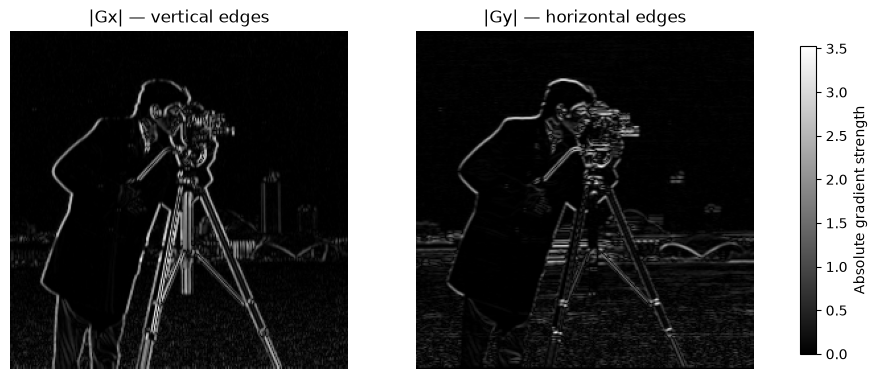

In [ ]:
##################
##      C6      ##
##################

I = util.img_as_float(original_cameraman)
##use the function
Gx, Gy, G, theta = sobelXY(I)
abs_Gx = np.abs(Gx)
abs_Gy = np.abs(Gy)

# display results
limit = max(abs_Gx.max(), abs_Gy.max())
if limit == 0:
    limit = 1.0
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_x = axes[0].imshow(abs_Gx, cmap="gray", vmin=0, vmax=limit)
axes[0].set_title("|Gx| — vertical edges")
axes[1].imshow(abs_Gy, cmap="gray", vmin=0, vmax=limit)
axes[1].set_title("|Gy| — horizontal edges")
for ax in axes:
    ax.axis("off")
fig.colorbar( plot_x, ax=axes, label="Absolute gradient strength",shrink=0.8)
plt.show()

## D. Frequency-domain filtering

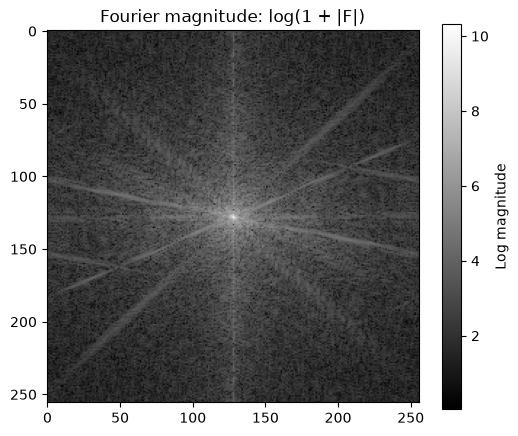

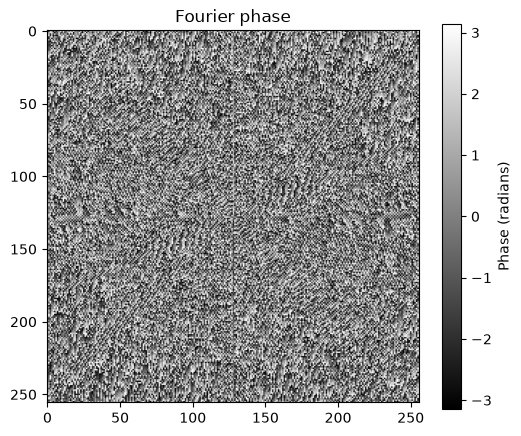

In [41]:
##################
##      D1      ##
##################

I = util.img_as_float(original_cameraman)

# Calculate the Fourier transform
F = np.fft.fft2(I)
# Move zero frequency to the centre
F = np.fft.fftshift(F)
# Calculate magnitude, then compress its range for display
magnitude = np.abs(F)
log_magnitude = np.log(1 + magnitude)
# Calculate phase in radians
phase = np.angle(F)


# DISPLAY MAGNITUDE AND PHASE
plt.figure(figsize=(6, 5))
plt.imshow(log_magnitude, cmap="gray")
plt.title("Fourier magnitude: log(1 + |F|)")
plt.colorbar(label="Log magnitude")
plt.show()
plt.figure(figsize=(6, 5))
plt.imshow(phase, cmap="gray", vmin=-np.pi, vmax=np.pi)
plt.title("Fourier phase")
plt.colorbar(label="Phase (radians)")
plt.show()

 * - the low frequincies appear closer to the center of the magnitude plot, where the high frequencies show further out


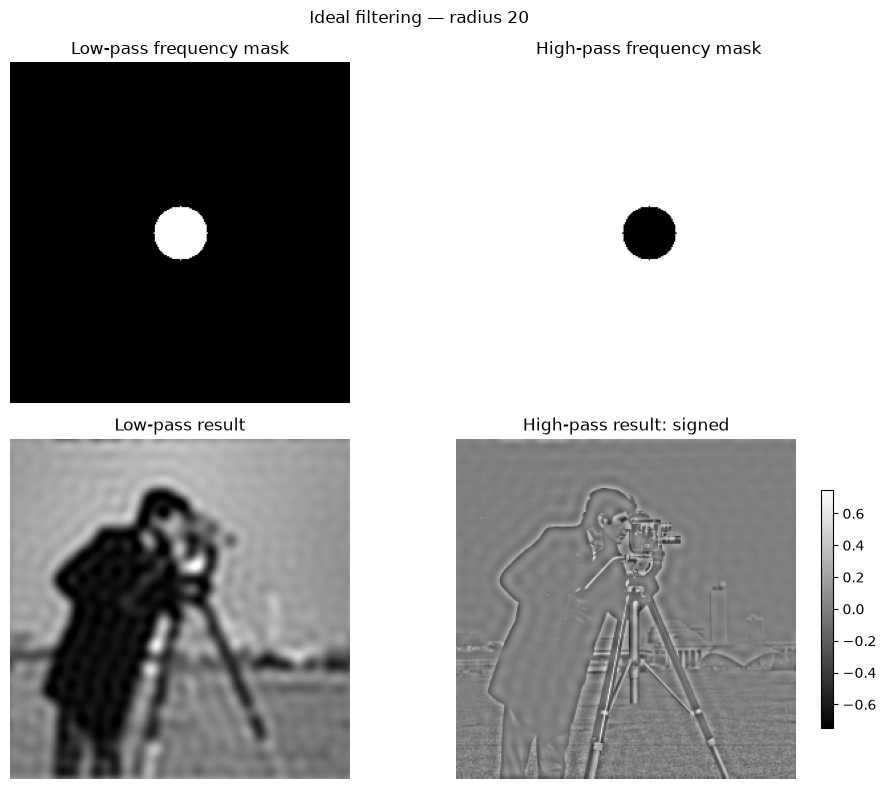

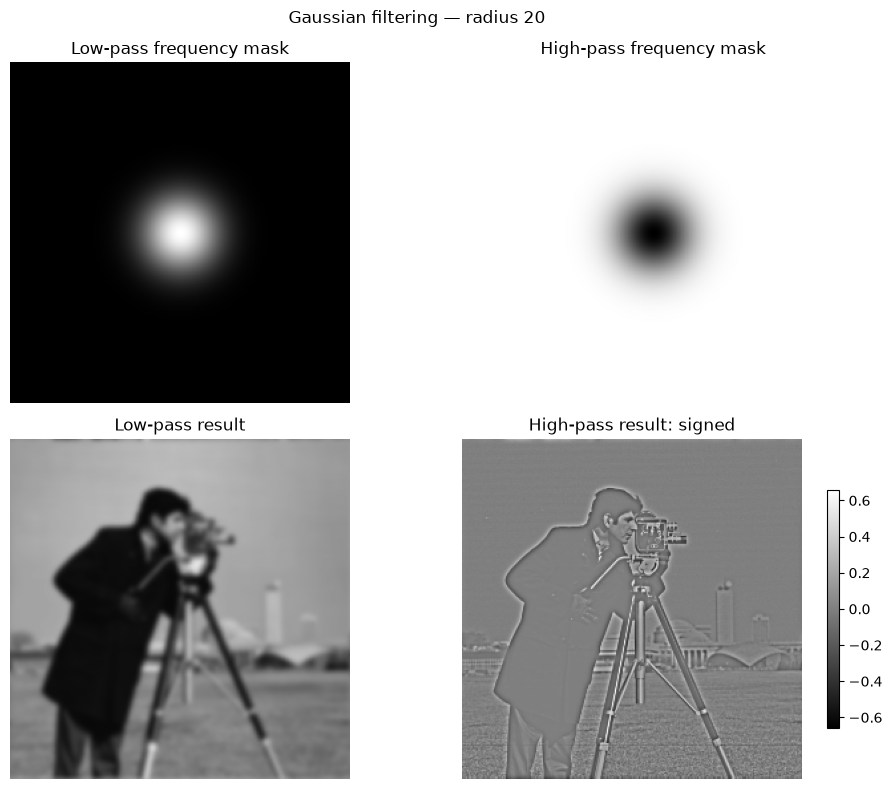

Radius 20: spatial sigma = (2.037, 2.037) pixels
Gaussian comparison MSE: 2.095786680554639e-11


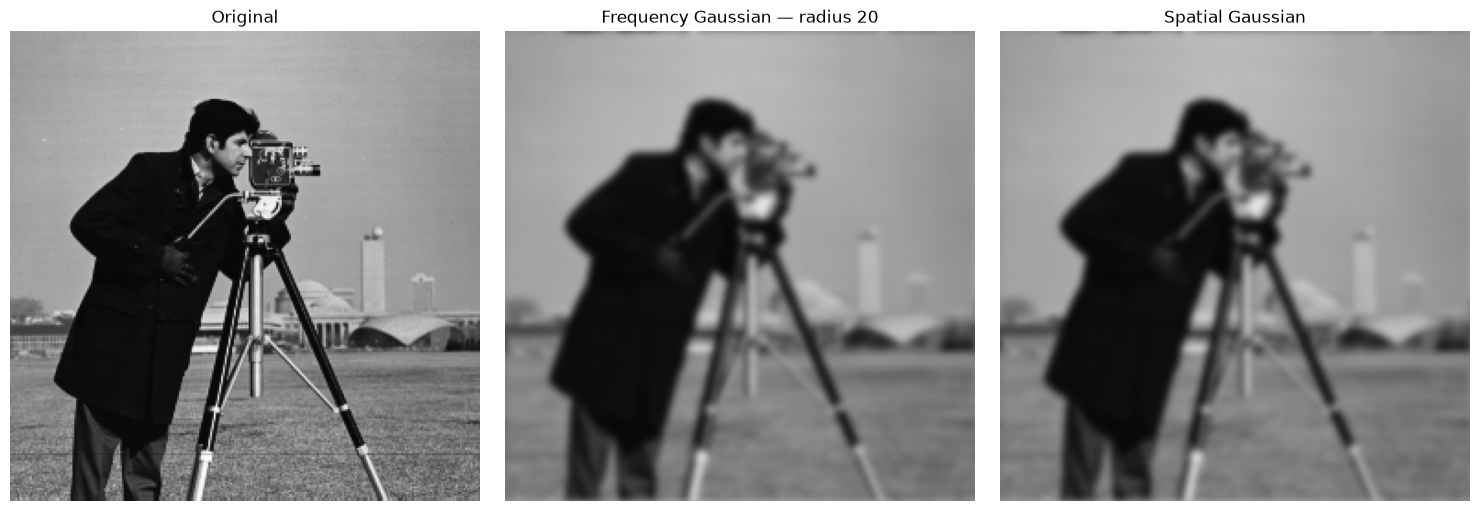

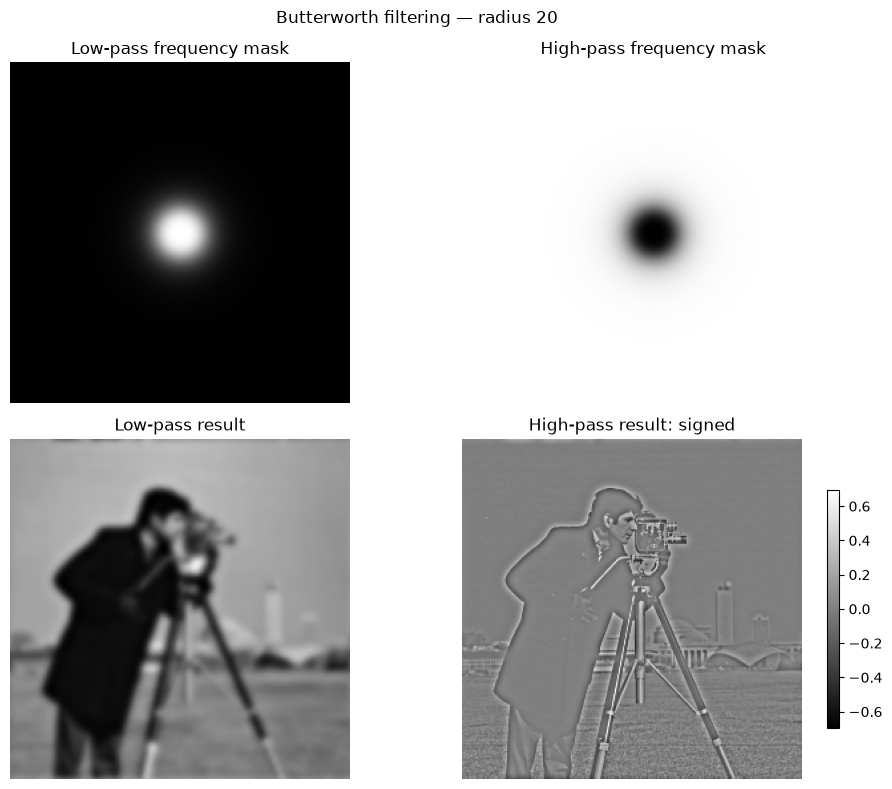

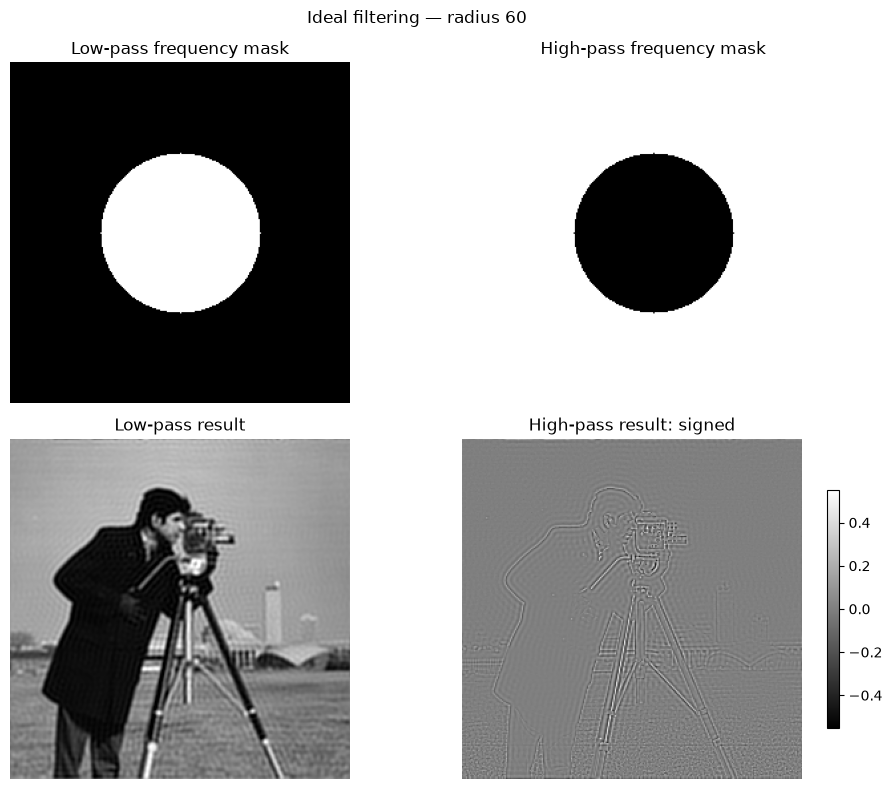

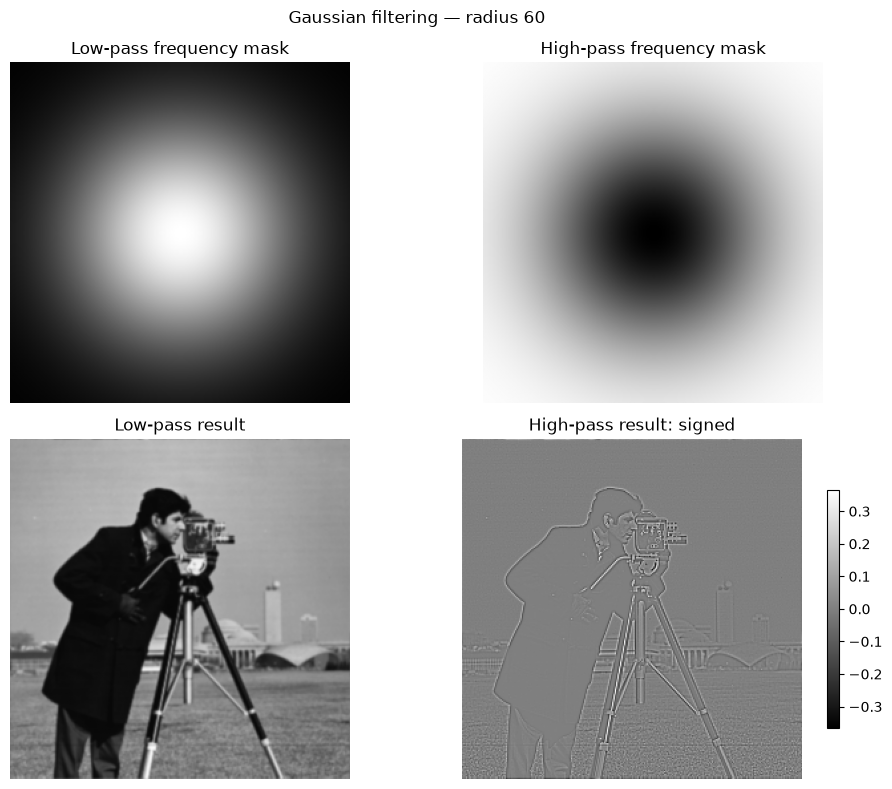

Radius 60: spatial sigma = (0.679, 0.679) pixels
Gaussian comparison MSE: 1.8782511040408756e-06


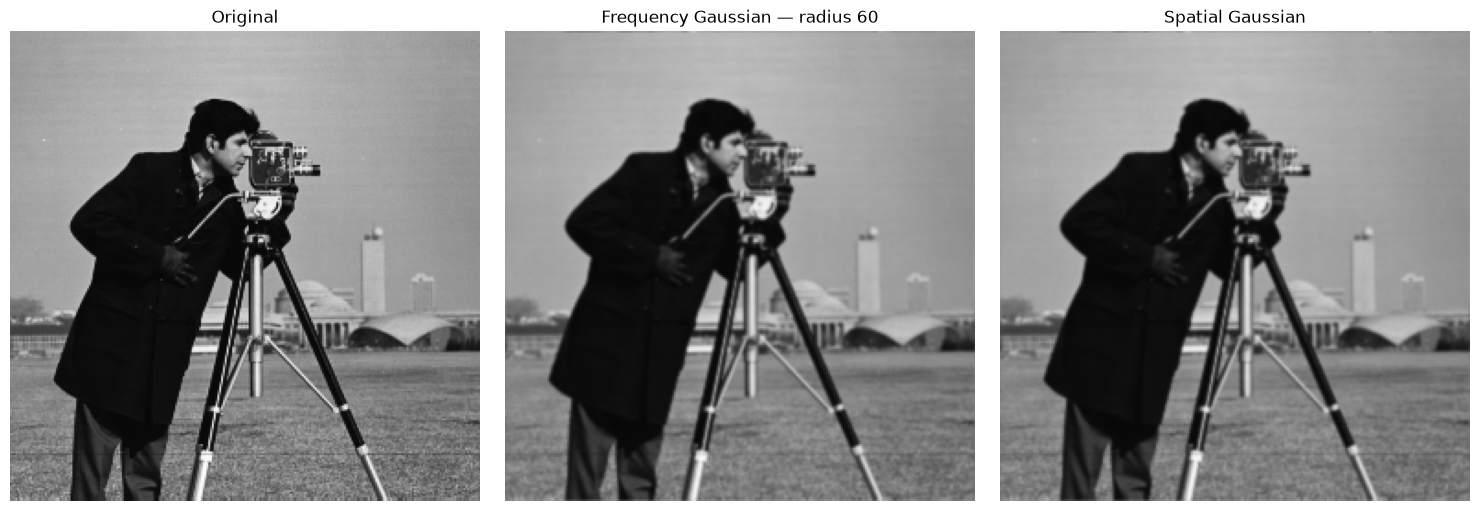

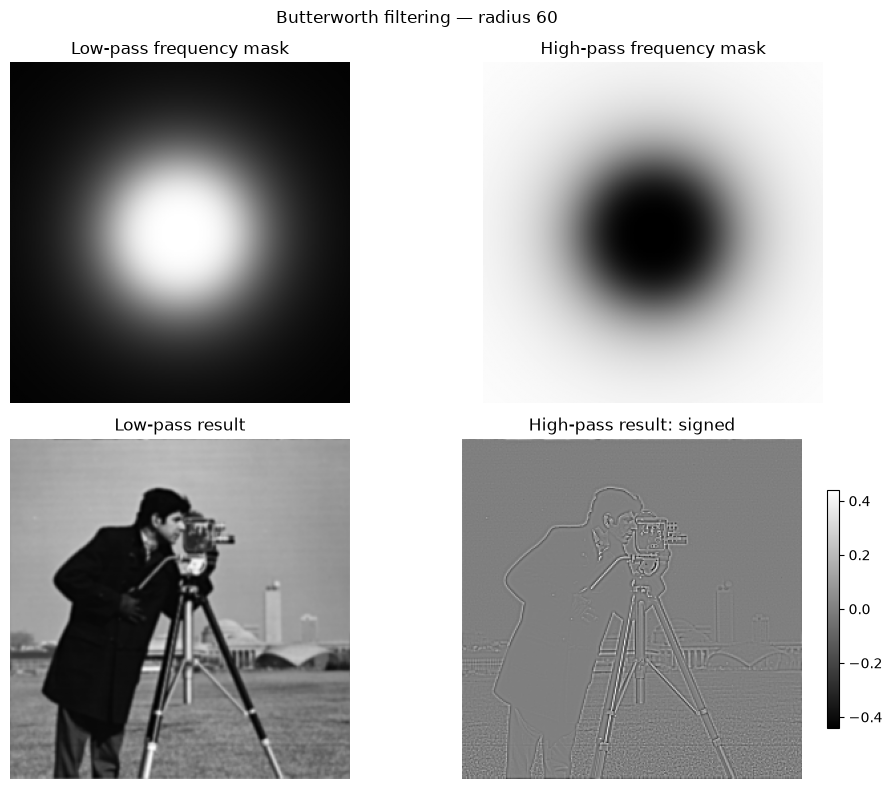

In [42]:
##################
##      D2      ##
##################

import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
from skimage import util

I = util.img_as_float(original_cameraman)

# Fourier transform, with zero frequency at the centre
F = np.fft.fft2(I)
F = np.fft.fftshift(F)

rows, columns = I.shape
centre_row = rows // 2
centre_column = columns // 2

# Calculate each frequency location's distance from the centre
distance = np.zeros((rows, columns), dtype=float)

for row in range(rows):
    for column in range(columns):
        y = row - centre_row
        x = column - centre_column
        distance[row, column] = np.sqrt(x * x + y * y)

cutoff_radii = [20, 60]
filter_names = ["Ideal", "Gaussian", "Butterworth"]

for cutoff in cutoff_radii:
    for filter_name in filter_names:
        # Create the low-pass filter
        if filter_name == "Ideal":
            low_pass = np.zeros_like(distance)
            low_pass[distance <= cutoff] = 1.0
        elif filter_name == "Gaussian":
            low_pass = np.exp(
                -(distance ** 2) / (2 * cutoff ** 2)
            )
        else:
            n = 2
            low_pass = 1 / (
                1 + (distance / cutoff) ** (2 * n)
            )

        # Its complementary high-pass filter
        high_pass = 1 - low_pass

        # Apply both filters to the original Fourier transform
        low_spectrum = F * low_pass
        high_spectrum = F * high_pass

        # Undo the shift before taking the inverse transform
        low_image = np.fft.ifft2(np.fft.ifftshift(low_spectrum) )
        high_image = np.fft.ifft2( np.fft.ifftshift(high_spectrum))

        # Discard small imaginary rounding errors
        low_image = low_image.real
        high_image = high_image.real

        # Show masks and reconstructed images
        fig, axes = plt.subplots(2, 2, figsize=(10, 8))
        fig.suptitle( f"{filter_name} filtering — radius {cutoff}")
        axes[0, 0].imshow(low_pass, cmap="gray", vmin=0, vmax=1)
        axes[0, 0].set_title("Low-pass frequency mask")
        axes[0, 1].imshow(  high_pass, cmap="gray", vmin=0, vmax=1 )
        axes[0, 1].set_title("High-pass frequency mask")
        axes[1, 0].imshow(low_image, cmap="gray", vmin=0, vmax=1 )
        axes[1, 0].set_title("Low-pass result")

        # High-pass results contain positive and negative values
        high_limit = np.max(np.abs(high_image))
        if high_limit == 0:
            high_limit = 1.0
        high_plot = axes[1, 1].imshow(  high_image, cmap="gray",  vmin=-high_limit,  vmax=high_limit )
        axes[1, 1].set_title("High-pass result: signed")
        fig.colorbar(high_plot, ax=axes[1, 1], shrink=0.7)
        for ax in axes.flat:
            ax.axis("off")
        plt.tight_layout()
        plt.show()

        # Additional comparison for Gaussian filtering
        if filter_name == "Gaussian":
            # Convert frequency radius to spatial Gaussian sigma
            sigma_rows = rows / (2 * np.pi * cutoff)
            sigma_columns = columns / (2 * np.pi * cutoff)
            spatial_gaussian = ndimage.gaussian_filter(I,sigma=(sigma_rows, sigma_columns),mode="wrap")
            print(
                f"Radius {cutoff}: "
                f"spatial sigma = "
                f"({sigma_rows:.3f}, {sigma_columns:.3f}) pixels"
            )
            difference = low_image - spatial_gaussian
            print("Gaussian comparison MSE:", np.mean(difference ** 2) )
            
            fig, axes = plt.subplots(1, 3, figsize=(15, 5))
            axes[0].imshow(I, cmap="gray", vmin=0, vmax=1 )
            axes[0].set_title("Original")
            axes[1].imshow(low_image, cmap="gray", vmin=0, vmax=1 )
            axes[1].set_title(  f"Frequency Gaussian — radius {cutoff}")
            axes[2].imshow( spatial_gaussian, cmap="gray",vmin=0,vmax=1)
            axes[2].set_title("Spatial Gaussian")
            for ax in axes:
                ax.axis("off")
            plt.tight_layout()
            plt.show()

**RADIUS 20**
* **IDEAL**: There appears to be very strong 'ringing', such that there are waves appearing around my image
* **GAUSSIAN & BUTTERWORTH**: If there are any differences they are very subtle. I think this is because they both reduce high frequencies gradually, but nevertheless they have very clear High-pass filtered images in the sense that you can easily see outlines etc . Close to the Signed Laplacian response observered earlier ( i think they both surpress uniform regions). However, the lowpass filter is extremely blurry and unsusable. I think this is due to the fact that low-pass filtering removes quick brightness changes like edges and there is alot of that present in the photo.

**RADIUS 60**
* **IDEAL**: Due to increasing the amount of frequencies allowed in the low pass, the low pass image is fairly clear and a much better step up than radius 20. I believe due to this change as well, the high pass image is very clearly lacking in any discernable detail (could be now that it can only show very rapid brightness changes, making things difficult to recognize).
* **GAUSSIAN & BUTTERWORTH**: For butterworth and gaussing the same effect kind of happens where the lowpass result is now usable but the issue is that the highpass result is now alot more lighter in color and the "edges" blend deeper in with the background.

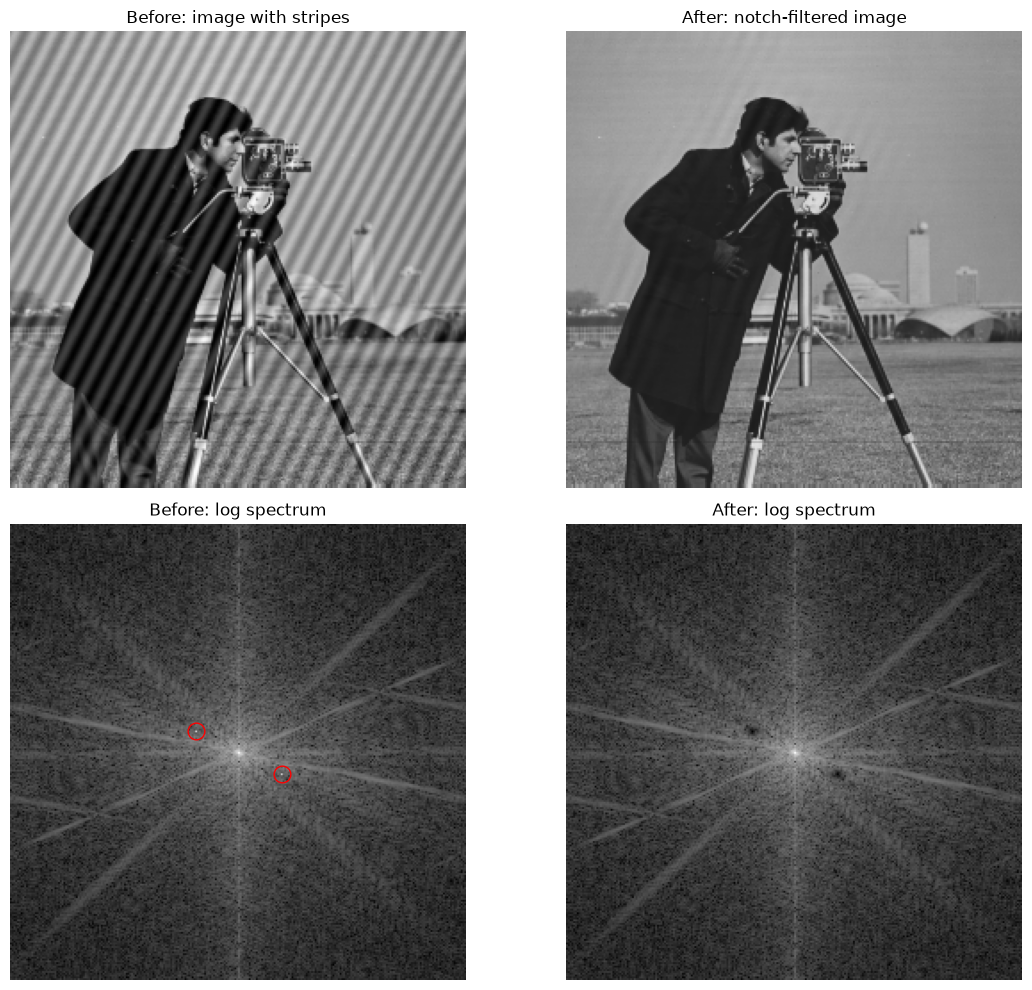

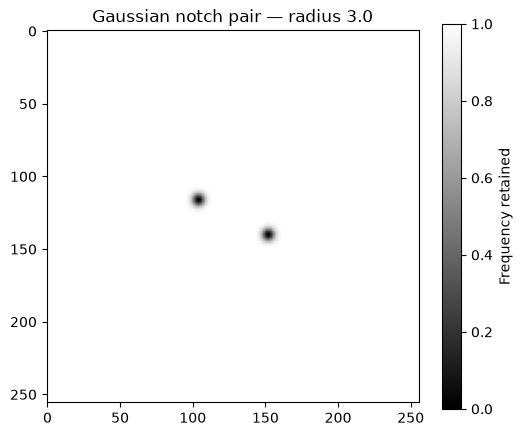

In [45]:
##################
##      D3      ##
##################

#STRIPE ADDING#
I = util.img_as_float(original_cameraman)
rows, columns = I.shape
# Number of cycles across the width and height
horizontal_cycles = 24
vertical_cycles = 12
amplitude = 0.15
stripes = np.zeros_like(I)
for row in range(rows):
    for column in range(columns):
        angle = 2 * np.pi * (
            horizontal_cycles * column / columns
            + vertical_cycles * row / rows
        )
        stripes[row, column] = amplitude * np.sin(angle)
noisy_image = I + stripes
noisy_spectrum = np.fft.fftshift(
    np.fft.fft2(noisy_image)
)

#NOTCH ADDING#
centre_row = rows // 2
centre_column = columns // 2
# Locations of the stripe peaks
peak1_row = centre_row + vertical_cycles
peak1_column = centre_column + horizontal_cycles
peak2_row = centre_row - vertical_cycles
peak2_column = centre_column - horizontal_cycles
notch_radius = 3.0
notch1 = np.zeros_like(I)
notch2 = np.zeros_like(I)
for row in range(rows):
    for column in range(columns):
        # Distances on the periodic Fourier grid
        dy1 = abs(row - peak1_row)
        dx1 = abs(column - peak1_column)
        dy1 = min(dy1, rows - dy1)
        dx1 = min(dx1, columns - dx1)
        dy2 = abs(row - peak2_row)
        dx2 = abs(column - peak2_column)
        dy2 = min(dy2, rows - dy2)
        dx2 = min(dx2, columns - dx2)
        distance1_squared = dy1 ** 2 + dx1 ** 2
        distance2_squared = dy2 ** 2 + dx2 ** 2
        notch1[row, column] = 1 - np.exp(-distance1_squared / (2 * notch_radius ** 2))
        notch2[row, column] = 1 - np.exp(-distance2_squared / (2 * notch_radius ** 2))
# Reject frequencies near either peak
combined_notch = notch1 * notch2


#FILTER AND IMAGE RECONSTRUCTION#
filtered_spectrum = noisy_spectrum * combined_notch
filtered_image = np.fft.ifft2(
    np.fft.ifftshift(filtered_spectrum)
).real
before_spectrum = np.log1p(np.abs(noisy_spectrum))
after_spectrum = np.log1p(np.abs(filtered_spectrum))
image_min = min(I.min(), noisy_image.min(), filtered_image.min())
image_max = max(I.max(), noisy_image.max(), filtered_image.max())
spectrum_min = min(before_spectrum.min(), after_spectrum.min())
spectrum_max = max(before_spectrum.max(), after_spectrum.max())

#DISPLAYING:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes[0, 0].imshow( noisy_image, cmap="gray",vmin=image_min, vmax=image_max)
axes[0, 0].set_title("Before: image with stripes")
axes[0, 1].imshow( filtered_image, cmap="gray", vmin=image_min, vmax=image_max)
axes[0, 1].set_title("After: notch-filtered image")
axes[1, 0].imshow( before_spectrum, cmap="gray", vmin=spectrum_min, vmax=spectrum_max)
axes[1, 0].set_title("Before: log spectrum")
# Mark the two locations being rejected
axes[1, 0].plot( [peak1_column, peak2_column],[peak1_row, peak2_row],"ro", fillstyle="none", markersize=12)
axes[1, 1].imshow(after_spectrum, cmap="gray", vmin=spectrum_min, vmax=spectrum_max)
axes[1, 1].set_title("After: log spectrum")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()
plt.figure(figsize=(6, 5))
plt.imshow(combined_notch, cmap="gray", vmin=0, vmax=1)
plt.title(f"Gaussian notch pair — radius {notch_radius}")
plt.colorbar(label="Frequency retained")
plt.show()

## E. Edge detection and robotics mini task

Gradient threshold: 0.5193007829447538


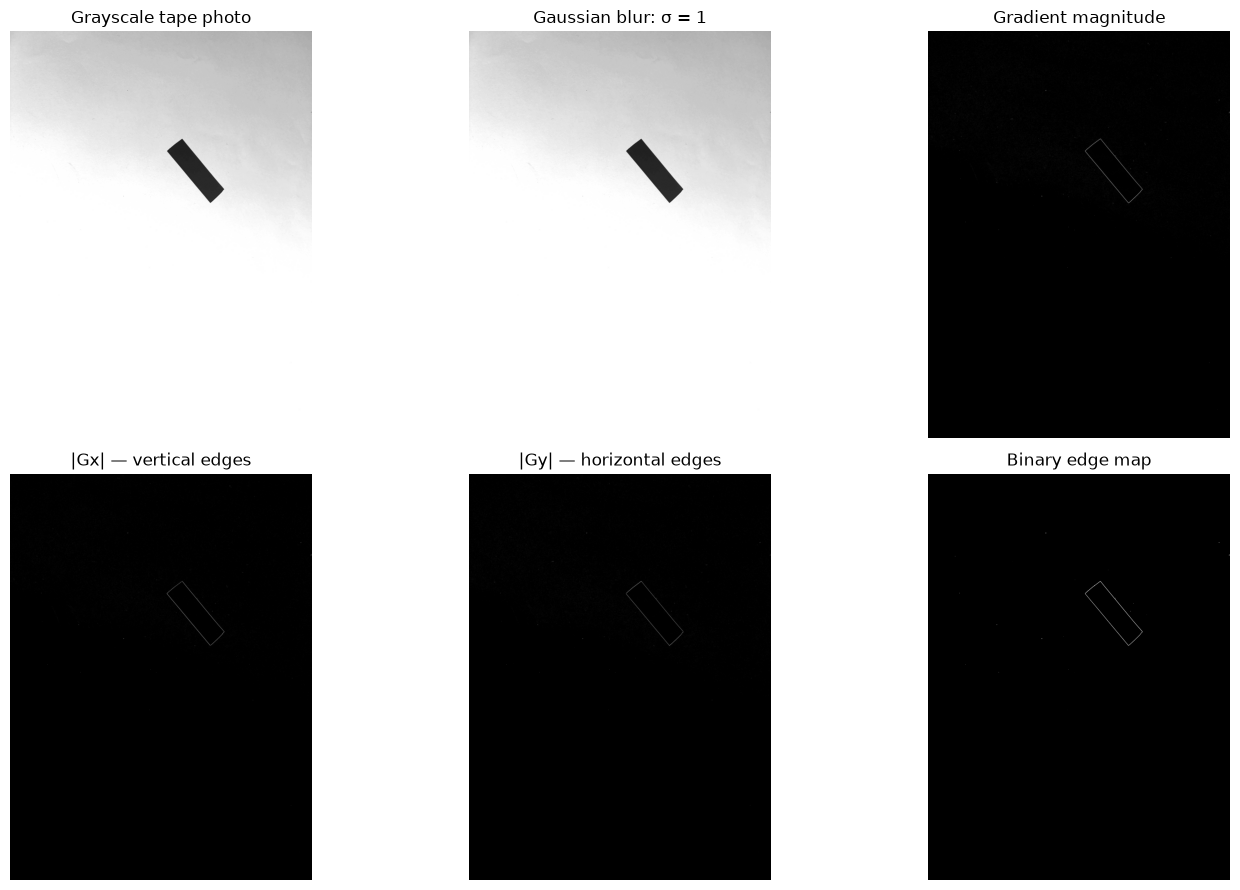

In [ ]:

##################
##      E1      ##
##################


from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
from skimage import io, color, util, filters

# Load the tape photo
tape_photo = io.imread(Path("data") / "tape photo.jpg")

# Convert to grayscale, with intensities between 0 and 1
if tape_photo.ndim == 3:
    tape_gray = color.rgb2gray(tape_photo)
else:
    tape_gray = util.img_as_float(tape_photo)

# Mild smoothing before calculating edges
tape_blurred = ndimage.gaussian_filter(
    tape_gray,
    sigma=1,
    mode="nearest"
)

# Use your own Sobel function
Gx, Gy, G, theta = sobelXY(tape_blurred)
vertical_edges = np.abs(Gx)
horizontal_edges = np.abs(Gy)

# Select a threshold from the gradient magnitude
edge_threshold = filters.threshold_otsu(G)
edge_map = G > edge_threshold
print("Gradient threshold:", edge_threshold)

# DISPLAY
gradient_limit = max(vertical_edges.max(), horizontal_edges.max())
if gradient_limit == 0:
    gradient_limit = 1.0
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes[0, 0].imshow(tape_gray, cmap="gray", vmin=0, vmax=1)
axes[0, 0].set_title("Grayscale tape photo")
axes[0, 1].imshow(tape_blurred, cmap="gray", vmin=0, vmax=1)
axes[0, 1].set_title("Gaussian blur: σ = 1")
axes[0, 2].imshow(G, cmap="gray", vmin=0, vmax=max(G.max(), 1e-12))
axes[0, 2].set_title("Gradient magnitude")
axes[1, 0].imshow(vertical_edges, cmap="gray",vmin=0, vmax=gradient_limit)
axes[1, 0].set_title("|Gx| — vertical edges")
axes[1, 1].imshow(horizontal_edges, cmap="gray",vmin=0, vmax=gradient_limit)
axes[1, 1].set_title("|Gy| — horizontal edges")
axes[1, 2].imshow(edge_map, cmap="gray", vmin=0, vmax=1)
axes[1, 2].set_title("Binary edge map")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

Line orientation from horizontal: -71.8°


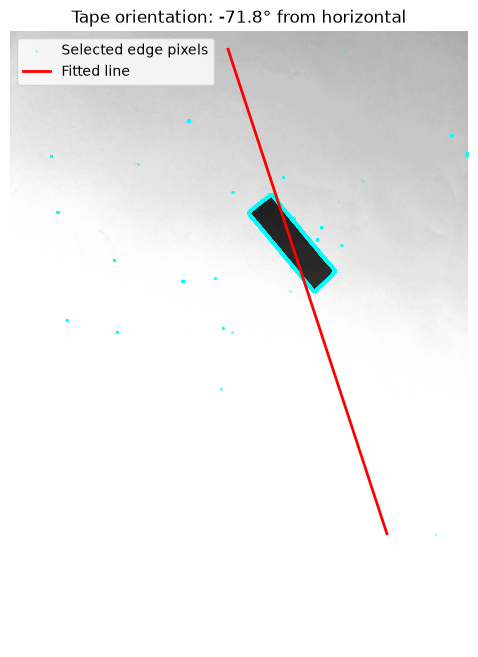

The tape points 18.2° left of robot-forward, ergo the robot should steer left by that amount.


In [46]:
##################
##      E2      ##
##################

# Region containing the tape: adjust these bounds as needed
height, width = edge_map.shape

row_start = 0
row_end = height
column_start = 0
column_end = width

# Keep only edges inside the selected rectangle
line_edges = np.zeros_like(edge_map, dtype=bool)
line_edges[
    row_start:row_end,
    column_start:column_end
] = edge_map[
    row_start:row_end,
    column_start:column_end
]

# Extract coordinates of the selected edge pixels
y_pixels, x_pixels = np.nonzero(line_edges)
if len(x_pixels) < 2:
    raise ValueError("Not enough edge pixels to fit a line.")
horizontal_span = np.ptp(x_pixels)
vertical_span = np.ptp(y_pixels)
if horizontal_span > vertical_span:
    # Mostly horizontal
    slope, intercept = np.polyfit(x_pixels, y_pixels, 1)

    x_fit = np.linspace(x_pixels.min(), x_pixels.max(), 200)
    y_fit = slope * x_fit + intercept
else:
    # Mostly vertical
    slope, intercept = np.polyfit(y_pixels, x_pixels, 1)

    y_fit = np.linspace(y_pixels.min(), y_pixels.max(), 200)
    x_fit = slope * y_fit + intercept

    dx = x_fit[-1] - x_fit[0]
dy = y_fit[-1] - y_fit[0]

# Orientation relative to horizontal, with positive angles upward
orientation = np.degrees(np.arctan2(-dy, dx))
# A line has the same orientation when its direction is reversed
orientation = (orientation + 90) % 180 - 90

print(f"Line orientation from horizontal: {orientation:.1f}°")
plt.figure(figsize=(8, 8))
plt.imshow(tape_gray, cmap="gray", vmin=0, vmax=1)
plt.scatter(
    x_pixels, y_pixels,
    s=1, color="cyan", alpha=0.3,
    label="Selected edge pixels"
)
plt.plot(
    x_fit, y_fit,
    color="red", linewidth=2,
    label="Fitted line"
)
plt.title(f"Tape orientation: {orientation:.1f}° from horizontal")
plt.legend()
plt.axis("off")
plt.show()


#steering interpretation:
# Reverse the direction if it currently points downward
if dy > 0:
    dx = -dx
    dy = -dy
# Positive means right of image-forward; negative means left
steering_angle = np.degrees(np.arctan2(dx, -dy))

if abs(steering_angle) < 1:
    interpretation = "The tape is approximately aligned with robot-forward."
elif steering_angle > 0:
    interpretation = (
        f"The tape points {steering_angle:.1f}° right of robot-forward, "
        "ergo the robot should steer right by that amount."
    )
else:
    interpretation = (
        f"The tape points {abs(steering_angle):.1f}° left of robot-forward, "
        "ergo the robot should steer left by that amount."
    )

print(interpretation)

## F. Reflection

* 1 - From the excercises in this assignment I would use frequency domain filtering if i needed to remove/isolate specific frequency patterns, like the strip noise, but for more local tasks like sharpening etc i would use spatial filtering.

* 2 - To be completely honest, the biggest surprise was how rotation was handled for me. I didnt expect that aliasing would be needing when you are just rotating a picture, but after some thought i think i can understand why. If we were rotating by 90 degree increments then the pixels are fully rotating, but when they are not fully rotated by 90 deg they are technically slanted and in practice you cant have slanted pixels.

*Please note: AI was used as an assist in the plotting of results for sections B onwards, and I also asked it to explain high level logic so i could try and implement the different principles myself